In [26]:
import cv2
import numpy as np
import sys
import matplotlib.pyplot as plt

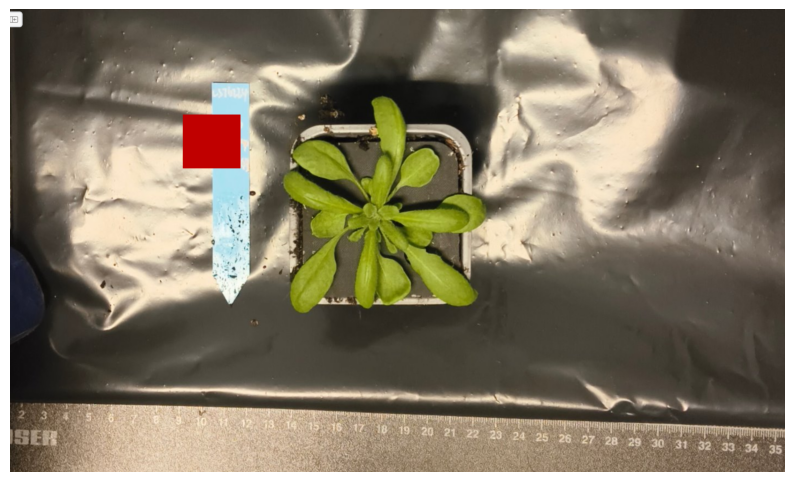

In [27]:
img_path = "/home/oscarareback/Pictures/Screenshots/Screenshot From 2026-11-26 08-42-22.png"


img = cv2.imread(img_path)

if img is None:
    raise ValueError("Could not load image")


img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 8))
plt.imshow(img_rgb)
plt.axis("off")
plt.show()

# Calibration

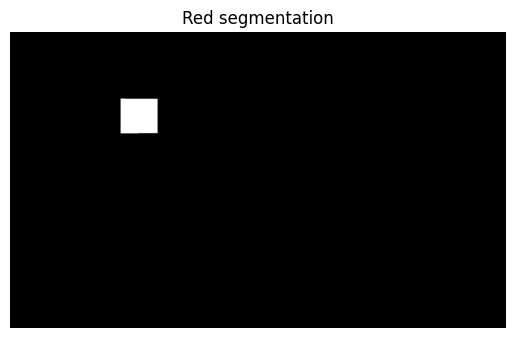

In [28]:
# Convert image to HSV colour space
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

# Define red colour ranges (Hue, Saturation, Value)
lower_red1 = np.array([0, 100, 70])
upper_red1 = np.array([10, 255, 255])

lower_red2 = np.array([170, 100, 70])
upper_red2 = np.array([179, 255, 255])

# Segment both red ranges
mask1 = cv2.inRange(hsv, lower_red1, upper_red1)
mask2 = cv2.inRange(hsv, lower_red2, upper_red2)

# Combine masks into a single binary image
mask = cv2.bitwise_or(mask1, mask2)

plt.imshow(mask, cmap="gray")
plt.title("Red segmentation")
plt.axis("off")
plt.show()

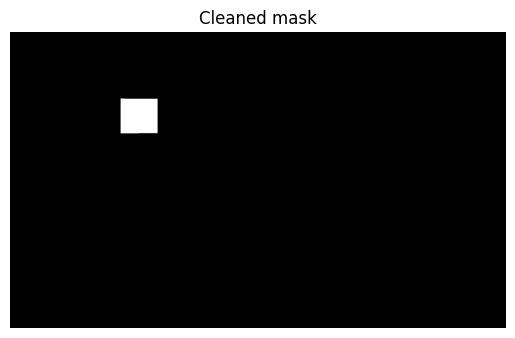

In [29]:
# Create a 3x3 morphological kernel
kernel = np.ones((3, 3), np.uint8)

# Remove small unwanted objects
clean_mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)

# Fill small holes and gaps
clean_mask = cv2.morphologyEx(clean_mask, cv2.MORPH_CLOSE, kernel)

plt.imshow(clean_mask, cmap="gray")
plt.title("Cleaned mask")
plt.axis("off")
plt.show()

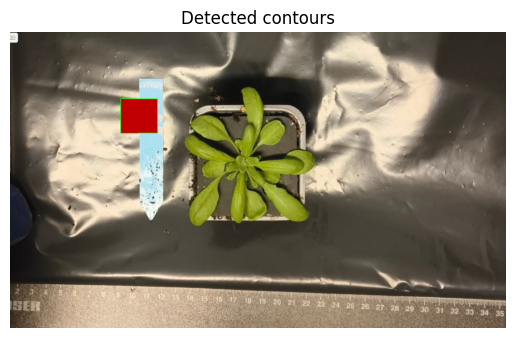

In [30]:
# Find boundaries of all segmented objects
contours, _ = cv2.findContours(
    clean_mask,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

# Create a copy of the original image
output = img_rgb.copy()

# Draw all detected contours in green
cv2.drawContours(output, contours, -1, (0, 255, 0), 2)

plt.imshow(output)
plt.title("Detected contours")
plt.axis("off")
plt.show()

Detected markers: 1


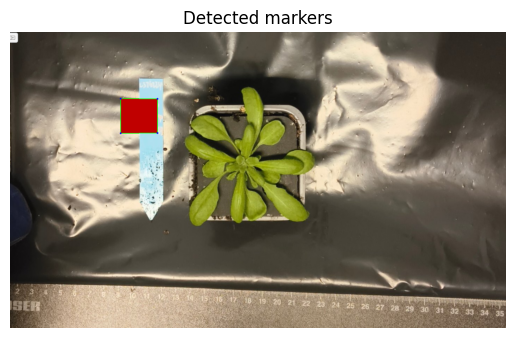

In [31]:
output = img_rgb.copy()
markers = []

for contour in contours:

    # Ignore small objects
    area = cv2.contourArea(contour)

    if area < 100:
        continue

    # Calculate contour perimeter
    perimeter = cv2.arcLength(contour, True)

    # Approximate contour as a polygon
    corners = cv2.approxPolyDP(contour, 0.02 * perimeter, True)

    # Require four corners and a convex shape
    if len(corners) != 4 or not cv2.isContourConvex(corners):
        continue

    # Calculate width and height of rotated rectangle
    _, (width, height), _ = cv2.minAreaRect(contour)

    # Check that width and height are approximately equal
    if min(width, height) / max(width, height) < 0.9:
        continue

    # Store detected marker
    markers.append(corners)

    # Draw marker outline
    cv2.drawContours(output, [corners], -1, (0, 255, 0), 2)

    # Draw marker corners
    for corner in corners:
        x, y = corner[0]
        cv2.circle(output, (x, y), 4, (0, 0, 255), -1)

print(f"Detected markers: {len(markers)}")

plt.imshow(output)
plt.title("Detected markers")
plt.axis("off")
plt.show()

In [32]:
# Physical marker dimensions in millimetres
MARKER_SIZE = 20.0
MARKER_AREA = MARKER_SIZE**2

for i, marker in enumerate(markers):

    # Calculate marker area in pixels
    pixel_area = cv2.contourArea(marker)

    # Calculate conversion factors
    mm2_per_pixel = MARKER_AREA / pixel_area
    mm_per_pixel = np.sqrt(mm2_per_pixel)

    print(f"Marker {i + 1}")
    print(f"Pixel area: {pixel_area:.2f} px²")
    print(f"Length scale: {mm_per_pixel:.4f} mm/px")
    print(f"Area scale: {mm2_per_pixel:.6f} mm²/px²")
    print()

Marker 1
Pixel area: 25092.00 px²
Length scale: 0.1263 mm/px
Area scale: 0.015941 mm²/px²



# Segmentation

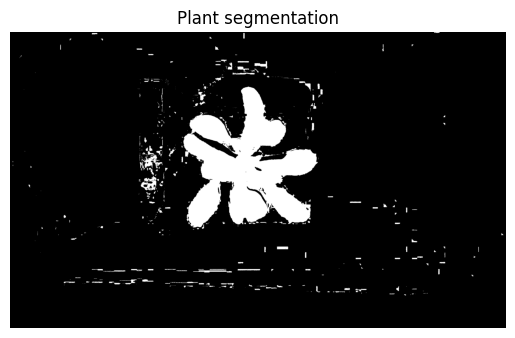

In [33]:
# Define green HSV range
lower_green = np.array([25, 40, 40])
upper_green = np.array([95, 255, 255])

# Create binary plant mask
plant_mask = cv2.inRange(hsv, lower_green, upper_green)

plt.imshow(plant_mask, cmap="gray")
plt.title("Plant segmentation")
plt.axis("off")
plt.show()

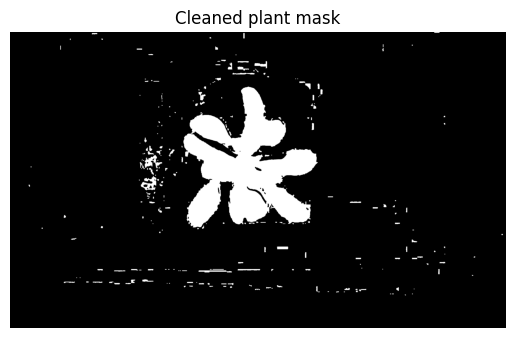

In [34]:
# Create morphological kernel
kernel = np.ones((3, 3), np.uint8)

# Remove small unwanted objects
clean_mask = cv2.morphologyEx(
    plant_mask, cv2.MORPH_OPEN, kernel
)

# Fill small gaps
clean_mask = cv2.morphologyEx(
    clean_mask, cv2.MORPH_CLOSE, kernel
)

plt.imshow(clean_mask, cmap="gray")
plt.title("Cleaned plant mask")
plt.axis("off")
plt.show()

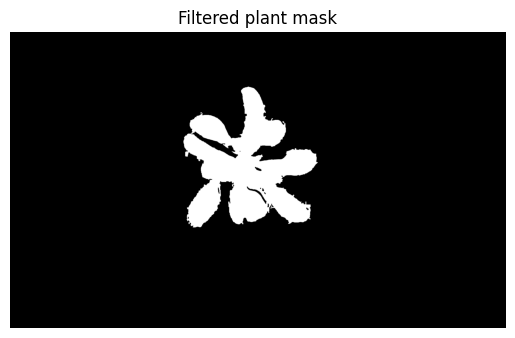

In [35]:
# Identify all connected objects in the binary mask
num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
    clean_mask, connectivity=8
)

# Ignore background (label 0)
if num_labels < 2:
    raise ValueError("No plant detected")

# Find the largest connected object
largest_label = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])

# Create a mask containing only the largest object
plant_mask = np.zeros_like(clean_mask)
plant_mask[labels == largest_label] = 255

plt.imshow(plant_mask, cmap="gray")
plt.title("Filtered plant mask")
plt.axis("off")
plt.show()

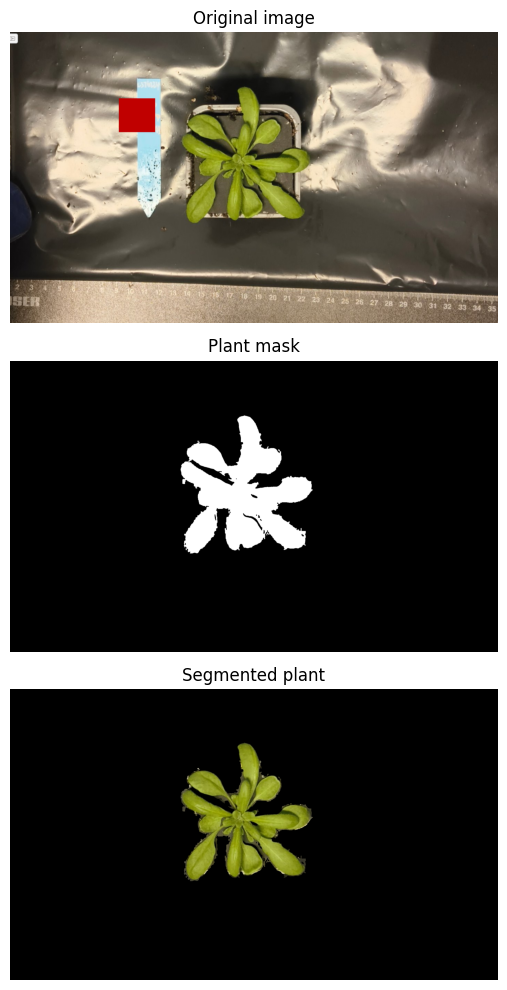

In [36]:
# Apply binary mask to the original image
segmented = cv2.bitwise_and(
    img_rgb, img_rgb, mask=plant_mask
)

# Compare the results
fig, ax = plt.subplots(3, 1, figsize=(8, 10))

ax[0].imshow(img_rgb)
ax[0].set_title("Original image")

ax[1].imshow(plant_mask, cmap="gray")
ax[1].set_title("Plant mask")

ax[2].imshow(segmented)
ax[2].set_title("Segmented plant")

for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

In [37]:
# Calculate and print plant area
plant_area_px = cv2.countNonZero(plant_mask)
plant_area_cm2 = plant_area_px * mm2_per_pixel / 100

print(f"Plant area: {plant_area_px} px²")
print(f"Plant area: {plant_area_cm2:.2f} cm²")

Plant area: 187104 px²
Plant area: 29.83 cm²


In [38]:
# Extract RGB values from segmented plant pixels
pixels = img_rgb[plant_mask > 0].astype(float)

# Separate colour channels
r = pixels[:, 0]
g = pixels[:, 1]
b = pixels[:, 2]

# Normalize colour channels to reduce brightness dependency
total = r + g + b + 1e-8

r = r / total
g = g / total
b = b / total

# Calculate Excess Green for each pixel
exg = 2 * g - r - b

# Calculate mean greenness
mean_exg = np.mean(exg)

print(f"Mean Excess Green: {mean_exg:.4f}")

Mean Excess Green: 0.3731
